# Where to zoom in: adaptive mesh refinement for viscous Burgers

A short, runnable tour of the study. It solves

$$u_t + (u^2/2)_x = \nu\, u_{xx}, \qquad u(x,0)=\sin(2\pi x)+0.5,$$

on a periodic domain, with small cells placed only where they are needed.

**How to use it:** Runtime → Run all (about a minute). Nothing to install. The functions are copied from
`amr_nonuniform.py` and `pareto_frontier.py` with their docstrings removed.

**Numbers here are a live demo.** The paper tunes every method to matched budgets and averages random runs,
so demo numbers illustrate each idea but are not the paper's results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Settings used throughout the study. Change these and re-run to experiment.
L, NU, T_FINAL = 1.0, 0.01, 0.3   # domain length, viscosity, final time
N0 = 32                           # starting (coarsest) number of cells

## 1. The cells and the flux
A mesh is just its sorted cell edges. Each cell stores one number, its average `u[i]`, and that changes only through
the fluxes across its two faces:

$$u_i^{new} = u_i - \frac{\Delta t}{h_i}\left(F_{i+1/2}-F_{i-1/2}\right)$$

Each face has **one** flux, shared by its two neighbours, which is why mass is conserved.

In [2]:
# Mesh helper: n equal cells
def uniform_edges(n_cells: int, L: float) -> np.ndarray:
    return np.linspace(0.0, L, n_cells + 1)

# Mesh helper: midpoint of each cell
def cell_centers(edges: np.ndarray) -> np.ndarray:
    return 0.5 * (edges[:-1] + edges[1:])

# Mesh helper: width of each cell
def cell_widths(edges: np.ndarray) -> np.ndarray:
    return np.diff(edges)

# Slope limiter: the smaller of two slopes, or 0 at a peak (no new wiggles)
def minmod(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    return np.where(a * b > 0, np.sign(a) * np.minimum(np.abs(a), np.abs(b)), 0.0)

# A limited slope for each cell, used by the second-order scheme
def limited_slopes(u: np.ndarray, edges: np.ndarray) -> np.ndarray:
    dx = cell_widths(edges)
    h_right = 0.5 * (dx + np.roll(dx, -1))
    h_left = 0.5 * (dx + np.roll(dx, 1))
    return minmod((np.roll(u, -1) - u) / h_right, (u - np.roll(u, 1)) / h_left)

# du/dt from flux differences. rusanov1 = flat cells; muscl2 = sloped cells
def burgers_rhs(u: np.ndarray, edges: np.ndarray, nu: float, scheme: str = "rusanov1") -> np.ndarray:
    dx = cell_widths(edges)
    u_right = np.roll(u, -1)
    dx_right = np.roll(dx, -1)
    h_face = 0.5 * (dx + dx_right)  # distance between cell i and i+1 centers

    if scheme == "rusanov1":
        uL, uR = u, u_right
    elif scheme == "muscl2":
        s = limited_slopes(u, edges)
        uL = u + 0.5 * dx * s                         # left state at face i+1/2
        uR = u_right - 0.5 * dx_right * np.roll(s, -1)  # right state at face i+1/2
    else:
        raise ValueError(f"unknown scheme: {scheme}")

    # Advective numerical flux at the face between cell i and cell i+1.
    # LOCAL Lax-Friedrichs: viscosity coefficient is computed PER FACE from
    # just the two neighboring face states, not a single global max over
    # the whole domain. This matters a lot for AMR specifically: with a
    # global alpha, numerical diffusion at a face is set by the fastest
    # wave speed ANYWHERE in the domain, so refining a cell locally doesn't
    # actually reduce the numerical diffusion smearing the shock there.
    alpha = np.maximum(np.abs(uL), np.abs(uR)) + 1e-12
    F_adv = 0.25 * (uL**2 + uR**2) - 0.5 * alpha * (uR - uL)

    # Diffusive numerical flux at the same face.
    F_diff = nu * (u_right - u) / h_face

    F = F_adv - F_diff
    return -(F - np.roll(F, 1)) / dx

# One time step: forward Euler (first order) or two-stage RK2 (second order)
def step_burgers_nonuniform(u: np.ndarray, edges: np.ndarray, dt: float, nu: float,
                            scheme: str = "rusanov1") -> np.ndarray:
    if scheme == "rusanov1":
        return u + dt * burgers_rhs(u, edges, nu, scheme)
    u1 = u + dt * burgers_rhs(u, edges, nu, scheme)
    return 0.5 * u + 0.5 * (u1 + dt * burgers_rhs(u1, edges, nu, scheme))

# One global time step, set by the SMALLEST cell
def stable_dt_nonuniform(u: np.ndarray, edges: np.ndarray, nu: float, cfl: float = 0.4) -> float:
    dx = cell_widths(edges)
    dx_min = dx.min()
    u_max = np.max(np.abs(u)) + 1e-12
    dt_advect = dx_min / u_max
    dt_diffuse = dx_min**2 / (2 * nu) if nu > 0 else np.inf
    return cfl * min(dt_advect, dt_diffuse)

## 2. Split and merge keep the total
The amount in a cell is width × value. These are the same worked numbers as on the slide, run through the real functions.

In [3]:
# Split marked cells in two. Linear mode tilts the halves by the slope; they still average to the parent
def refine(edges: np.ndarray, u: np.ndarray, marked: np.ndarray, prolong: str = "constant"):
    if prolong == "linear":
        offset = 0.25 * cell_widths(edges) * limited_slopes(u, edges)
    elif prolong == "constant":
        offset = np.zeros_like(u)
    else:
        raise ValueError(f"unknown prolongation: {prolong}")
    new_edges = [edges[0]]
    new_u = []
    for i in range(len(u)):
        left, right = edges[i], edges[i + 1]
        if marked[i]:
            mid = 0.5 * (left + right)
            new_edges.append(mid)
            new_edges.append(right)
            new_u.append(u[i] - offset[i])
            new_u.append(u[i] + offset[i])
        else:
            new_edges.append(right)
            new_u.append(u[i])
    return np.array(new_edges), np.array(new_u)

# Merge marked pairs into one cell using the width-weighted average
def coarsen(edges: np.ndarray, u: np.ndarray, marked_pairs: np.ndarray):
    n = len(u)
    dx = cell_widths(edges)
    new_edges = [edges[0]]
    new_u = []
    i = 0
    while i < n:
        if marked_pairs[i] and i + 1 < n:
            left, right = edges[i], edges[i + 2]
            w1, w2 = dx[i], dx[i + 1]
            merged_val = (w1 * u[i] + w2 * u[i + 1]) / (w1 + w2)
            new_edges.append(right)
            new_u.append(merged_val)
            i += 2
        else:
            new_edges.append(edges[i + 1])
            new_u.append(u[i])
            i += 1
    return np.array(new_edges), np.array(new_u)

In [4]:
# REFINE: one cell of width 0.1 and value 0.6, whose neighbours make its limited slope 2
edges = np.array([0.0, 0.1, 0.2, 0.3])
u = np.array([0.4, 0.6, 0.8])
print("limited slopes:", limited_slopes(u, edges))     # the periodic ends differ; the middle cell is what we split
new_edges, new_u = refine(edges, u, np.array([False, True, False]), prolong="linear")
print("refined values:", new_u[1:3])
print("parent amount :", 0.1 * 0.6)
print("children total:", np.sum(cell_widths(new_edges)[1:3] * new_u[1:3]))

# COARSEN: two halves with values 0.9 and 0.5 merge into one cell
edges = np.array([0.0, 0.05, 0.1])
u = np.array([0.9, 0.5])
new_edges, new_u = coarsen(edges, u, np.array([True, False]))
print("\nmerged value  :", new_u)
print("before / after:", np.sum(cell_widths(edges) * u), np.sum(cell_widths(new_edges) * new_u))

limited slopes: [0. 2. 0.]
refined values: [0.55 0.65]
parent amount : 0.06
children total: 0.06

merged value  : [0.7]
before / after: 0.07 0.07


## 3. Scoring cells: steepness or bend
Both scores are finite-difference derivatives. On a straight ramp the second derivative is zero, so the bend score ignores it.

In [5]:
# Steepness score: h * |u'|
def gradient_indicator_nonuniform(u: np.ndarray, edges: np.ndarray) -> np.ndarray:
    dx = cell_widths(edges)
    u_left = np.roll(u, 1)
    u_right = np.roll(u, -1)
    h_left = np.roll(dx, 1)
    h_right = dx
    slope = (u_right - u_left) / (h_left + h_right)
    return dx * np.abs(slope)

# Bend score: h^2 * |u''|
def curvature_indicator_nonuniform(u: np.ndarray, edges: np.ndarray) -> np.ndarray:
    dx = cell_widths(edges)
    h_right = 0.5 * (dx + np.roll(dx, -1))
    h_left = 0.5 * (dx + np.roll(dx, 1))
    u_xx = 2.0 * ((np.roll(u, -1) - u) / h_right - (u - np.roll(u, 1)) / h_left) / (h_left + h_right)
    return dx**2 * np.abs(u_xx)

INDICATORS = {"gradient": gradient_indicator_nonuniform, "curvature": curvature_indicator_nonuniform}

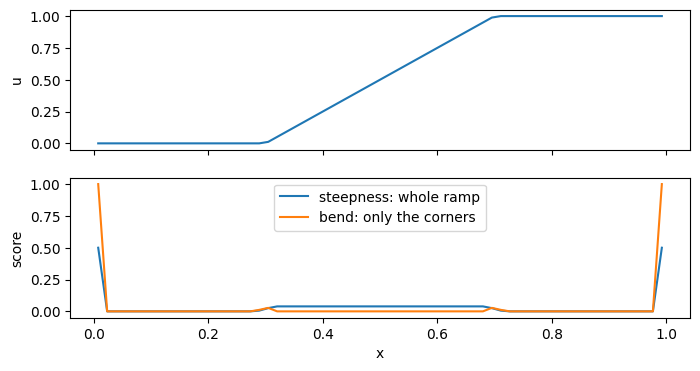

In [6]:
# A profile: flat, then a straight ramp, then flat. Compare where each score is large.
edges = uniform_edges(64, 1.0)
x = cell_centers(edges)
u = np.clip((x - 0.3) / 0.4, 0, 1)

fig, ax = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
ax[0].plot(x, u); ax[0].set_ylabel("u")
ax[1].plot(x, gradient_indicator_nonuniform(u, edges), label="steepness: whole ramp")
ax[1].plot(x, curvature_indicator_nonuniform(u, edges), label="bend: only the corners")
ax[1].set_ylabel("score"); ax[1].set_xlabel("x"); ax[1].legend()
plt.show()

## 4. The three rules for picking cells
Random (Gumbel) top-K is ordinary top-K after adding random noise to the scores. `temperature` sets how random it is.

In [7]:
# Threshold rule: every cell above a fraction of the largest score
def mark_hysteresis(indicator: np.ndarray, frac_hi: float, frac_lo: float) -> np.ndarray:
    tau_hi = frac_hi * indicator.max()
    return indicator > tau_hi

# Merge candidates: cells below a small fraction of the largest score
def unmark_hysteresis(indicator: np.ndarray, frac_lo: float) -> np.ndarray:
    tau_lo = frac_lo * indicator.max()
    return indicator < tau_lo

# Top-K: the K highest scores among cells that can still be split
def mark_deterministic_topk(indicator: np.ndarray, K: int, eligible: np.ndarray = None) -> np.ndarray:
    if eligible is None:
        eligible = np.ones_like(indicator, dtype=bool)
    idx = np.flatnonzero(eligible)
    K = min(K, len(idx))
    mask = np.zeros_like(indicator, dtype=bool)
    if K > 0:
        mask[idx[np.argpartition(indicator[idx], -K)[-K:]]] = True
    return mask

# Random top-K: add Gumbel noise to the scores, then take the top K
def mark_gumbel_topk(indicator: np.ndarray, K: int, temperature: float, rng: np.random.Generator,
                     eligible: np.ndarray = None) -> np.ndarray:
    if eligible is None:
        eligible = np.ones_like(indicator, dtype=bool)
    eps = 1e-12
    normalized = indicator / (indicator.max() + eps)
    scores = normalized / (temperature + eps)
    u = rng.uniform(size=len(indicator))
    gumbel_noise = -np.log(-np.log(u + eps) + eps)
    perturbed = np.where(eligible, scores + gumbel_noise, -np.inf)
    idx = np.flatnonzero(eligible)
    K = min(K, len(idx))
    mask = np.zeros_like(indicator, dtype=bool)
    if K > 0:
        mask[idx[np.argpartition(perturbed[idx], -K)[-K:]]] = True
    return mask

In [8]:
# Run the rules on the same scores. Re-run this cell: only the random rule changes.
score = np.array([0.1, 0.3, 1.0, 0.8, 0.2, 0.6, 0.05, 0.4])
rng = np.random.default_rng()
print("scores        ", score)
print("threshold 0.35", mark_hysteresis(score, 0.35, 0.05).astype(int))
print("top-3         ", mark_deterministic_topk(score, 3).astype(int))
print("random top-3  ", mark_gumbel_topk(score, 3, temperature=0.3, rng=rng).astype(int))

scores         [0.1  0.3  1.   0.8  0.2  0.6  0.05 0.4 ]
threshold 0.35 [0 0 1 1 0 1 0 1]
top-3          [0 0 1 1 0 1 0 0]
random top-3   [0 0 1 1 0 1 0 0]


## 5. The full adaptive loop
Every `T_FINAL / 20` the code checks a gate. If one cell stands out from the typical cell (ratio at least 3.5), it picks cells,
splits them, and merges true sibling pairs where the score is low.

In [9]:
# How many times each cell has been split
def cell_levels(edges: np.ndarray, base_width: float) -> np.ndarray:
    return np.rint(np.log2(base_width / cell_widths(edges))).astype(int)

# True where cells i and i+1 are the two halves of one parent (only these may merge)
def sibling_pairs(edges: np.ndarray, base_width: float) -> np.ndarray:
    level = cell_levels(edges, base_width)
    width = base_width / 2.0**level
    lattice_idx = np.rint(edges[:-1] / width).astype(int)
    same_level = np.zeros(len(level), dtype=bool)
    same_level[:-1] = level[:-1] == level[1:]
    return same_level & (level >= 1) & (lattice_idx % 2 == 0)

# One pick / split / merge pass. All rules share the same merge policy
def regrid(edges: np.ndarray, u: np.ndarray, marker: str, frac_lo: float,
           max_level_width: float, marker_kwargs: dict = None, rng: np.random.Generator = None,
           base_width: float = None, prolong: str = "constant", indicator: str = "gradient"):
    marker_kwargs = marker_kwargs or {}
    estimate = INDICATORS[indicator]
    eta = estimate(u, edges)
    dx = cell_widths(edges)
    if base_width is None:
        base_width = dx.max()
    # Eligibility is applied INSIDE the K-based markers (see
    # mark_deterministic_topk) so they refine exactly K eligible cells.
    # Hysteresis is a threshold rule with no budget, so masking after
    # selection is equivalent for it.
    eligible = dx > max_level_width * (1 + 1e-9)

    if marker == "hysteresis":
        refine_mask = mark_hysteresis(eta, marker_kwargs["frac_hi"], frac_lo)
    elif marker == "topk":
        refine_mask = mark_deterministic_topk(eta, marker_kwargs["K"], eligible)
    elif marker == "gumbel_topk":
        refine_mask = mark_gumbel_topk(eta, marker_kwargs["K"], marker_kwargs["temperature"], rng,
                                       eligible)
    else:
        raise ValueError(f"unknown marker: {marker}")

    refine_mask = refine_mask & eligible
    edges, u = refine(edges, u, refine_mask, prolong)

    # Recompute after refine before considering coarsening, so we don't
    # immediately re-merge cells we just split. Coarsen policy is shared
    # across all three markers -- isolates the refine rule as the only
    # experimental variable.
    #
    # Only true siblings are merged. The earlier rule merged ANY adjacent
    # pair of low-indicator cells, which produced non-nested cells of
    # mixed width (e.g. 3/64) and cells coarser than the base mesh -- so
    # the coarse regions could end up LESS resolved than a uniform n0
    # grid, adding numerical diffusion that had nothing to do with the
    # marking rule. Restricting to siblings keeps the mesh dyadic and
    # bounds every cell's width by base_width.
    indicator2 = estimate(u, edges)
    coarsen_candidate = unmark_hysteresis(indicator2, frac_lo)
    both_candidates = coarsen_candidate & np.roll(coarsen_candidate, -1) & sibling_pairs(edges, base_width)
    edges, u = coarsen(edges, u, both_candidates)

    return edges, u, refine_mask

# The gate: steepest cell / typical cell, always using the steepness score
def indicator_contrast(u: np.ndarray, edges: np.ndarray) -> float:
    ind = gradient_indicator_nonuniform(u, edges)
    return ind.max() / (np.median(ind) + 1e-12)

# Which locations are at the finest level (used for grid turnover)
def refined_occupancy(edges: np.ndarray, ref_points: np.ndarray, refined_width_cutoff: float) -> np.ndarray:
    cell_idx = np.searchsorted(edges, ref_points, side="right") - 1
    cell_idx = np.clip(cell_idx, 0, len(edges) - 2)
    widths = cell_widths(edges)
    return widths[cell_idx] <= refined_width_cutoff

# How much the finest-level region moved between two events
def jaccard_distance(mask_a: np.ndarray, mask_b: np.ndarray) -> float:
    union = np.sum(mask_a | mask_b)
    if union == 0:
        return 0.0
    intersection = np.sum(mask_a & mask_b)
    return 1.0 - intersection / union

# The main loop: step in time, and regrid at fixed simulation times
def run_adaptive(n0: int, L: float, nu: float, t_final: float,
                  marker: str, marker_kwargs: dict, frac_lo: float,
                  regrid_dt: float = None, max_level_width: float = None,
                  cfl: float = 0.4, min_contrast: float = 3.5, seed: int = 0,
                  stats: dict = None, scheme: str = "rusanov1", prolong: str = None,
                  indicator: str = "gradient"):
    if prolong is None:
        prolong = "linear" if scheme == "muscl2" else "constant"
    if max_level_width is None:
        max_level_width = (L / n0) / 8  # allow up to 3 refinement levels
    if regrid_dt is None:
        regrid_dt = t_final / 20  # ~20 regrid opportunities over the run

    rng = np.random.default_rng(seed)
    ref_points = np.linspace(0, L, 2048, endpoint=False)

    def initial_condition(x):
        return np.sin(2 * np.pi * x / L) + 0.5

    edges = uniform_edges(n0, L)
    u = initial_condition(cell_centers(edges))

    t = 0.0
    next_regrid_t = regrid_dt
    snapshots = [(t, edges.copy(), u.copy())]
    occupancy_history = []
    turnover = []
    base_width = L / n0
    if stats is None:
        stats = {}
    stats.update(n_steps=0, cell_updates=0, n_refined=[], n_coarsened=[], min_width=base_width, max_width=base_width)

    while t < t_final:
        dt = stable_dt_nonuniform(u, edges, nu, cfl)
        dt = min(dt, t_final - t, next_regrid_t - t if next_regrid_t > t else dt)
        u = step_burgers_nonuniform(u, edges, dt, nu, scheme)
        t += dt
        stats["n_steps"] += 1
        stats["cell_updates"] += len(u)

        if t >= next_regrid_t - 1e-12:
            next_regrid_t += regrid_dt
            if indicator_contrast(u, edges) >= min_contrast:
                n_before = len(u)
                edges, u, refine_mask = regrid(edges, u, marker, frac_lo, max_level_width,
                                                marker_kwargs, rng, base_width, prolong, indicator)
                stats["n_refined"].append(int(refine_mask.sum()))
                # each merge removes one cell: before + refined - merged = after
                stats["n_coarsened"].append(n_before + int(refine_mask.sum()) - len(u))
                widths = cell_widths(edges)
                stats["min_width"] = min(stats["min_width"], widths.min())
                stats["max_width"] = max(stats["max_width"], widths.max())
                snapshots.append((t, edges.copy(), u.copy()))

                occ = refined_occupancy(edges, ref_points, max_level_width * 1.5)
                # Turnover is only defined between two events that BOTH have
                # cells at the finest level. Two empty sets would give a
                # distance of 0 (no change measured, because there was
                # nothing to measure) and empty -> non-empty always gives 1
                # (first appearance, not churn); counting either biased the
                # mean, and made runs that never reach the finest level
                # report a spurious turnover of exactly 0.
                if occupancy_history and occ.any() and occupancy_history[-1].any():
                    turnover.append(jaccard_distance(occ, occupancy_history[-1]))
                occupancy_history.append(occ)

    snapshots.append((t, edges.copy(), u.copy()))
    return snapshots, turnover

In [10]:
# Starting profile
def initial_condition(x, L):
    return np.sin(2 * np.pi * x / L) + 0.5

# The baseline: every cell the same size
def run_uniform(n: int, L: float, nu: float, t_final: float, cfl: float = 0.4,
                scheme: str = "rusanov1", return_steps: bool = False):
    edges = uniform_edges(n, L)
    u = initial_condition(cell_centers(edges), L)
    t, n_steps = 0.0, 0
    while t < t_final:
        dt = stable_dt_nonuniform(u, edges, nu, cfl)
        dt = min(dt, t_final - t)
        u = step_burgers_nonuniform(u, edges, dt, nu, scheme)
        t += dt
        n_steps += 1
    return (edges, u, n_steps) if return_steps else (edges, u)

# Error against a very fine reference solution
def l2_error_against_reference(edges: np.ndarray, u: np.ndarray,
                                x_ref: np.ndarray, u_ref: np.ndarray, dx_ref: float) -> float:
    centers = cell_centers(edges)
    # np.interp needs an ascending x array with period; wrap manually for periodicity.
    u_on_ref = np.interp(x_ref, centers, u, period=x_ref[-1] + dx_ref)
    return np.sqrt(dx_ref * np.sum((u_on_ref - u_ref) ** 2))

In [11]:
# Fine reference solutions, one per scheme. The study uses 4096 cells; 2048 keeps this demo quick.
N_REF = 2048
dx_ref = L / N_REF
REF = {}
for s in ["rusanov1", "muscl2"]:
    e, u_ref = run_uniform(N_REF, L, NU, T_FINAL, scheme=s)
    REF[s] = (cell_centers(e), u_ref)

def demo(marker, kw, scheme="muscl2", indicator="gradient", min_contrast=3.5, seed=0):
    # Run one adaptive configuration and report what it cost and how accurate it was
    stats = {}
    snaps, _ = run_adaptive(N0, L, NU, T_FINAL, marker, kw, frac_lo=0.05, regrid_dt=T_FINAL / 20,
                            min_contrast=min_contrast, seed=seed, stats=stats, scheme=scheme, indicator=indicator)
    t, edges, u = snaps[-1]
    x_ref, u_ref = REF[scheme]
    mass = [np.sum(cell_widths(e) * v) for _, e, v in snaps]
    return dict(cells=len(u), work=stats["cell_updates"], steps=stats["n_steps"],
                error=l2_error_against_reference(edges, u, x_ref, u_ref, dx_ref),
                drift=max(abs(m - mass[0]) for m in mass), edges=edges, u=u, stats=stats)

def show(name, r):
    print(f"{name:34s} cells {r['cells']:4d}   work {r['work']:7d}   steps {r['steps']:5d}   error {r['error']:.5f}")

def uniform(n, scheme="muscl2"):
    # The same report for a uniform grid
    e, u, steps = run_uniform(n, L, NU, T_FINAL, scheme=scheme, return_steps=True)
    x_ref, u_ref = REF[scheme]
    return dict(cells=n, work=n * steps, steps=steps, error=l2_error_against_reference(e, u, x_ref, u_ref, dx_ref))

## 6. See the mesh follow the front
Ticks show cell edges: packed under the front, wide elsewhere.

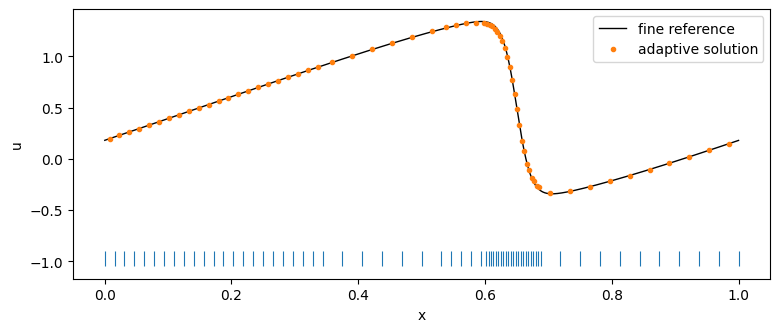

top-K, K=5                         cells   65   work   19226   steps   378   error 0.00724


In [12]:
r = demo("topk", {"K": 5})
fig, ax = plt.subplots(figsize=(9, 3.5))
x_ref, u_ref = REF["muscl2"]
ax.plot(x_ref, u_ref, "k", lw=1, label="fine reference")
ax.plot(cell_centers(r["edges"]), r["u"], "o", ms=3, color="tab:orange", label="adaptive solution")
ax.vlines(r["edges"], -1.05, -0.9, color="tab:blue", lw=0.8)
ax.set_xlabel("x"); ax.set_ylabel("u"); ax.legend(); plt.show()
show("top-K, K=5", r)

## 7. The findings, live
Parameters below are hand-picked for a quick demo, so cell counts are close but not matched. Compare **work** and **error**, not just cells.

In [13]:
print("--- A. The rule (second-order scheme) ---")
show("threshold, frac=0.3", demo("hysteresis", {"frac_hi": 0.3}))
show("top-K, K=5", demo("topk", {"K": 5}))
show("random top-K, K=5, seed 0", demo("gumbel_topk", {"K": 5, "temperature": 0.1}, seed=0))
show("random top-K, K=5, seed 1", demo("gumbel_topk", {"K": 5, "temperature": 0.1}, seed=1))

print("\n--- B. The method: same rule, first vs second order ---")
show("top-K, first order", demo("topk", {"K": 5}, scheme="rusanov1"))
show("top-K, second order", demo("topk", {"K": 5}, scheme="muscl2"))

print("\n--- C. The score: steepness vs bend ---")
show("top-K, steepness", demo("topk", {"K": 5}, indicator="gradient"))
show("top-K, bend", demo("topk", {"K": 5}, indicator="curvature"))

print("\n--- D. The baseline: uniform grids ---")
for n in [64, 128, 256]:
    show(f"uniform, n={n}", uniform(n))

--- A. The rule (second-order scheme) ---


threshold, frac=0.3                cells   80   work   26048   steps   378   error 0.00656


top-K, K=5                         cells   65   work   19226   steps   378   error 0.00724


random top-K, K=5, seed 0          cells   64   work   23084   steps   452   error 0.00666


random top-K, K=5, seed 1          cells   66   work   21580   steps   415   error 0.00803

--- B. The method: same rule, first vs second order ---
top-K, first order                 cells   57   work   17678   steps   369   error 0.04349


top-K, second order                cells   65   work   19226   steps   378   error 0.00724

--- C. The score: steepness vs bend ---


top-K, steepness                   cells   65   work   19226   steps   378   error 0.00724
top-K, bend                        cells   60   work   18746   steps   359   error 0.00607

--- D. The baseline: uniform grids ---


uniform, n=64                      cells   64   work    4416   steps    69   error 0.01992
uniform, n=128                     cells  128   work   31488   steps   246   error 0.00597


uniform, n=256                     cells  256   work  251904   steps   984   error 0.00159


In [14]:
# E. Why cell count is not cost: halve the smallest cell and the global step shrinks
for n in [32, 64, 128, 256, 512]:
    e = uniform_edges(n, L)
    dt = stable_dt_nonuniform(np.sin(2 * np.pi * cell_centers(e)) + 0.5, e, NU)
    print(f"smallest cell 1/{n:<4d} global step {dt:.2e}")
print("\nOnce the diffusion limit takes over, each halving makes the step 4x shorter.")

smallest cell 1/32   global step 8.36e-03
smallest cell 1/64   global step 4.17e-03
smallest cell 1/128  global step 1.22e-03
smallest cell 1/256  global step 3.05e-04
smallest cell 1/512  global step 7.63e-05

Once the diffusion limit takes over, each halving makes the step 4x shorter.


## 8. The checks that catch quiet bugs
Three bugs in this project produced believable numbers. These simplified checks from `check_mesh.py` must always pass.

In [15]:
base = L / N0
for name, marker, kw in [("threshold", "hysteresis", {"frac_hi": 0.3}), ("top-K", "topk", {"K": 5}),
                         ("random top-K", "gumbel_topk", {"K": 5, "temperature": 0.1})]:
    r = demo(marker, kw)
    assert r["stats"]["max_width"] <= base * (1 + 1e-9), "a cell got coarser than the starting mesh"
    assert r["drift"] < 1e-12, "mass was not conserved"
    print(f"PASS  {name:13s} largest cell {r['stats']['max_width']:.5f} <= {base:.5f}   mass drift {r['drift']:.1e}")

# Top-K must split exactly K cells whenever K cells are eligible
score, eligible = np.random.default_rng(0).random(40), np.ones(40, dtype=bool)
eligible[:35] = False
assert mark_deterministic_topk(score, 3, eligible).sum() == 3
assert mark_gumbel_topk(score, 3, 0.1, np.random.default_rng(0), eligible).sum() == 3
print("PASS  top-K rules split exactly K eligible cells")

# Accuracy must improve at the rate theory predicts when the grid is refined
print("\nObserved order of accuracy on uniform grids (against the fine reference):")
for s in ["rusanov1", "muscl2"]:
    errs = [uniform(n, s)["error"] for n in [128, 256]]
    print(f"  {s}: {np.log2(errs[0] / errs[1]):.2f}")

PASS  threshold     largest cell 0.03125 <= 0.03125   mass drift 2.2e-16


PASS  top-K         largest cell 0.03125 <= 0.03125   mass drift 1.1e-16


PASS  random top-K  largest cell 0.03125 <= 0.03125   mass drift 2.2e-16
PASS  top-K rules split exactly K eligible cells

Observed order of accuracy on uniform grids (against the fine reference):
  rusanov1: 1.07


  muscl2: 1.90
